# Notebook 2: Instance log analysis (`history/last_month/instance_log.csv`)

In this notebook I look at every machine that was rented last month. I want to know when each one started, when it could take work, how long it was billed, how much of its capacity was used, and how its cost splits between start-up, running queries and sitting ready but idle.

This matters because Part 1 of the assignment asks *"How much of [the spend] paid for machines that were sitting idle?"*. The bill in Notebook 1 only tells me how many hours were paid for. This file tells me how many of those hours were actually used.

To understand the file, I checked the simulator source. `simkit/engine.py` writes one row per instance in `_terminate`, at the moment the instance is terminated:

| column | how the engine fills it |
|---|---|
| `instance_id` | `f"{type}-{'od' or 'sp'}-{counter:05d}"` |
| `launched_s` | the time `launch()` was called (billing starts here) |
| `ready_s` | the time the instance became `ready` (launch + `join_s` + `ready_s` from the config); empty if it never became ready |
| `terminated_s` | the time it was terminated |
| `reason` | `scheduler`, `spot_interruption` or `end_of_simulation` |
| `billed_s` | `max(terminated - launched, minimum_s)` |
| `cost_usd` | the per-second charges added up |
| `busy_slot_s` | the running time of every query that ran on it, added together (one query uses one slot) |
| `utilization` | `busy_slot_s / (slots * billed_s)`, rounded to 4 decimals |

This means `busy_slot_s` is measured in **slot-seconds**. One slot busy for one second is 1 slot-second, so a 16-slot machine running for one second offers 16 slot-seconds.

The notebook is organised as follows:

1. Setup and loading
2. Structure and data quality
3. Instances, machine types and markets
4. Lifecycle: launch, readiness, termination
5. Billed duration and cost per instance
6. Busy slot-seconds and utilisation (recomputed correctly)
7. Cross-check against the query log
8. Cost allocation: start-up vs execution vs ready-idle
9. Summary

## 1. Setup and loading

In this step I import the libraries, find `history/last_month/` (this works from the project root or from `analysis/`), and load the instance log and the config.

I need the config because the instance log does not include the number of slots per machine. That number is in `config["instance_types"][type]["slots"]`, and I cannot calculate utilisation without it.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)


def find_history_dir() -> Path:
    """Return the history/last_month folder, searching upwards from the working directory."""
    for base in [Path.cwd(), *Path.cwd().parents]:
        candidate = base / "history" / "last_month"
        if candidate.is_dir():
            return candidate
    raise FileNotFoundError("Could not find history/last_month. Run from the project folder or analysis/.")


HISTORY_DIR = find_history_dir()
TYPE_ORDER = ["std.small", "std.large", "mem.xlarge"]
TYPE_COLORS = {"std.small": "#2a78d6", "std.large": "#eb6834", "mem.xlarge": "#1baf7a"}
plt.rcParams.update({
    "figure.figsize": (10, 4), "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.edgecolor": "#c3c2b7",
    "axes.titleweight": "bold", "lines.linewidth": 2,
})

instances = pd.read_csv(HISTORY_DIR / "instance_log.csv")
with open(HISTORY_DIR / "config.json") as f:
    config = json.load(f)
instances

,instance_id,instance_type,market,launched_s,ready_s,terminated_s,reason,billed_s,cost_usd,busy_slot_s,utilization
0,std.small-od-00001,std.small,on_demand,0.0000,135.0000,"2,601,000.0000",end_of_simulation,"2,601,000.0000",72.2500,106.2000,0.0000
1,std.small-od-00002,std.small,on_demand,0.0000,135.0000,"2,601,000.0000",end_of_simulation,"2,601,000.0000",72.2500,"91,057.4000",0.0175
2,std.large-od-00003,std.large,on_demand,0.0000,240.0000,"2,601,000.0000",end_of_simulation,"2,601,000.0000",491.3000,"38,079.6000",0.0018
3,std.large-od-00004,std.large,on_demand,0.0000,240.0000,"2,601,000.0000",end_of_simulation,"2,601,000.0000",491.3000,"5,053,619.2000",0.2429
4,std.large-od-00005,std.large,on_demand,0.0000,240.0000,"2,601,000.0000",end_of_simulation,"2,601,000.0000",491.3000,"2,374,396.4000",0.1141
5,std.large-od-00006,std.large,on_demand,0.0000,240.0000,"2,601,000.0000",end_of_simulation,"2,601,000.0000",491.3000,"10,968,748.3000",0.5271
6,std.large-od-00007,std.large,on_demand,0.0000,240.0000,"2,601,000.0000",end_of_simulation,"2,601,000.0000",491.3000,"451,784.4000",0.0217
7,std.large-od-00008,std.large,on_demand,0.0000,240.0000,"2,601,000.0000",end_of_simulation,"2,601,000.0000",491.3000,"52,804.1000",0.0025
8,mem.xlarge-od-00009,mem.xlarge,on_demand,0.0000,570.0000,"2,601,000.0000",end_of_simulation,"2,601,000.0000","1,965.2000","13,631,349.7000",0.3276
9,mem.xlarge-od-00010,mem.xlarge,on_demand,0.0000,570.0000,"2,601,000.0000",end_of_simulation,"2,601,000.0000","1,965.2000","11,337,291.0000",0.2724


The whole file is only 14 rows, one per machine, so I can read all of it.

A few things are visible straight away:

- every machine has `launched_s = 0.0` and `terminated_s = 2,601,000.0`;
- every `reason` is `end_of_simulation`;
- `utilization` varies a lot between machines of the *same* type (for example, `std.large` goes from 0.0018 to 0.5271).

I check these observations with code below instead of relying on a quick look.

## 2. Structure and data quality

Here I check the shape of the table, the column types, missing values, duplicate IDs, and whether the timestamps are consistent with each other.

With only 14 rows, one bad row would distort every percentage. I also check the engine's own definitions:

- `ready_s >= launched_s` and `terminated_s >= ready_s` (time moves forward);
- `billed_s = max(terminated_s - launched_s, billing minimum)`;
- `busy_slot_s <= slots * (terminated_s - ready_s)` (a machine cannot be busier than the capacity it had while ready).

In [2]:
print("Rows, columns:", instances.shape)
print("\nData types:\n", instances.dtypes, sep="")
print("\nMissing values:\n", instances.isna().sum(), sep="")
print("\nDuplicate instance_id:", instances["instance_id"].duplicated().sum())

instances["slots"] = instances["instance_type"].map(lambda t: config["instance_types"][t]["slots"])
min_bill = config["billing"]["minimum_s"]
checks = {
    "ready_s >= launched_s": (instances["ready_s"] >= instances["launched_s"]).all(),
    "terminated_s >= ready_s": (instances["terminated_s"] >= instances["ready_s"]).all(),
    "billed_s == max(life, minimum)": np.allclose(
        instances["billed_s"], np.maximum(instances["terminated_s"] - instances["launched_s"], min_bill)),
    "busy <= slots x ready time": (instances["busy_slot_s"]
                                    <= instances["slots"] * (instances["terminated_s"] - instances["ready_s"]) + 1e-6).all(),
}
for name, ok in checks.items():
    print(f"{name:35s} {'OK' if ok else 'FAILED'}")
assert all(checks.values())

Rows, columns: (14, 11)

Data types:
instance_id          str
instance_type        str
market               str
launched_s       float64
ready_s          float64
terminated_s     float64
reason               str
billed_s         float64
cost_usd         float64
busy_slot_s      float64
utilization      float64
dtype: object

Missing values:
instance_id      0
instance_type    0
market           0
launched_s       0
ready_s          0
terminated_s     0
reason           0
billed_s         0
cost_usd         0
busy_slot_s      0
utilization      0
dtype: int64

Duplicate instance_id: 0
ready_s >= launched_s               OK
terminated_s >= ready_s             OK
billed_s == max(life, minimum)      OK
busy <= slots x ready time          OK


The table has 14 rows and 11 columns. There are no missing values (every machine became ready, so `ready_s` is always filled), no duplicate IDs, and all four consistency checks pass. The `billed_s` check confirms that billing ran from launch to termination, including the time spent joining and warming up.

So the file agrees with the engine's definitions, and I can calculate with it.

## 3. Instances, machine types and markets

Here I count how many machines of each type and market were used, and show their specification from the config.

I need to compare utilisation and cost *within* a machine type, because a 2-slot machine and a 16-slot machine are not comparable one to one.

In [3]:
spec_cols = ["slots", "on_demand_usd_per_hr", "spot_usd_per_hr", "join_s", "ready_s"]
specs = pd.DataFrame(config["instance_types"]).T[spec_cols].rename(columns={"ready_s": "warmup_s"})
fleet = (instances.groupby(["instance_type", "market"]).size().rename("machines").reset_index()
         .merge(specs, left_on="instance_type", right_index=True))
fleet["total_slots"] = fleet["machines"] * fleet["slots"]
fleet = fleet.set_index("instance_type").loc[TYPE_ORDER].reset_index()
print("Total machines:", fleet["machines"].sum(), "| total slots:", int(fleet["total_slots"].sum()))
print("Markets used:", sorted(instances["market"].unique()))
fleet

Total machines: 14 | total slots: 148
Markets used: ['on_demand']


,instance_type,market,machines,slots,on_demand_usd_per_hr,spot_usd_per_hr,join_s,warmup_s,total_slots
0,std.small,on_demand,2,2.0000,0.1000,0.0350,45.0000,90.0000,4.0000
1,std.large,on_demand,6,8.0000,0.6800,0.2200,60.0000,180.0000,48.0000
2,mem.xlarge,on_demand,6,16.0000,2.7200,0.9500,90.0000,480.0000,96.0000


There were **14 machines**: 2 `std.small` (4 slots), 6 `std.large` (48 slots) and 6 `mem.xlarge` (96 slots), which is **148 slots** in total.

All of them were **on-demand**. No spot machines were ever launched, so **no spot interruptions could have happened** last month.

Most of the slot capacity (96 of the 148 slots) was on the most expensive machine type.

## 4. Lifecycle: launch, readiness and termination

In this section I look at how long each machine took to go from launch to ready (the start-up delay), how long it was ready for, why it was terminated, and whether the machines ran for the whole simulation.

Start-up time is billed, but no queries can run during it. A scheduler that launches machines when they are needed pays this delay every time, and the queries waiting for that machine have to wait too. If start-up is long compared with the work, scaling up late can cause SLA misses.

I use these formulas:

- `startup_s = ready_s - launched_s` (booting + warming)
- `expected_startup_s = join_s + ready_s` from the config
- `ready_time_s = terminated_s - ready_s`
- `life_s = terminated_s - launched_s`

One thing to be careful about: the config value called `ready_s` is the *warm-up duration*, while the log column called `ready_s` is a *timestamp*. They have the same name but mean different things, which is why I renamed the config value to `warmup_s` above.

In [4]:
instances["startup_s"] = instances["ready_s"] - instances["launched_s"]
instances["expected_startup_s"] = instances["instance_type"].map(
    lambda t: config["instance_types"][t]["join_s"] + config["instance_types"][t]["ready_s"])
instances["ready_time_s"] = instances["terminated_s"] - instances["ready_s"]
instances["life_s"] = instances["terminated_s"] - instances["launched_s"]

assert np.allclose(instances["startup_s"], instances["expected_startup_s"]), "start-up differs from config"

duration_s = config["duration_s"]
lifecycle = instances.groupby("instance_type").agg(
    machines=("instance_id", "size"),
    launched_min=("launched_s", "min"), launched_max=("launched_s", "max"),
    startup_s=("startup_s", "first"),
    terminated_min=("terminated_s", "min"), terminated_max=("terminated_s", "max"),
).loc[TYPE_ORDER]
print("Termination reasons:\n", instances["reason"].value_counts(), sep="")
print(f"\nConfigured month length: {duration_s:,} s = {duration_s / 86400:.0f} days")
print(f"Last termination:        {instances['terminated_s'].max():,.0f} s "
      f"= {instances['terminated_s'].max() / 86400:.4f} days "
      f"({(instances['terminated_s'].max() - duration_s) / 3600:.2f} h after the month ended)")
lifecycle

Termination reasons:
reason
end_of_simulation    14
Name: count, dtype: int64

Configured month length: 2,592,000 s = 30 days
Last termination:        2,601,000 s = 30.1042 days (2.50 h after the month ended)


,machines,launched_min,launched_max,startup_s,terminated_min,terminated_max
instance_type,,,,,,
std.small,2,0.0000,0.0000,135.0000,"2,601,000.0000","2,601,000.0000"
std.large,6,0.0000,0.0000,240.0000,"2,601,000.0000","2,601,000.0000"
mem.xlarge,6,0.0000,0.0000,570.0000,"2,601,000.0000","2,601,000.0000"


The start-up delays match the config exactly: 135 seconds for `std.small` (45 seconds to join and 90 to warm up), 240 seconds for `std.large`, and 570 seconds (9.5 minutes) for `mem.xlarge`.

All machines were launched at `t = 0` and all were terminated at `t = 2,601,000 s` with the reason `end_of_simulation`. **No machine was ever stopped by the scheduler.** The fleet kept running the whole time.

The last termination happened **2.5 hours after the 30-day month ended**. The engine keeps going until every query has finished, and the fixed fleet was billed for that tail.

For the scheduler, this means a `mem.xlarge` costs about 9.5 minutes of billing before it can do anything. For short work, such as a `dashboard` with a 10-second SLA, a newly launched machine can never help the query that caused the launch, so capacity for tight SLAs has to be running already. For long work, such as a `report` with a 6 to 12 hour SLA, a 9.5-minute start-up is affordable.

## 5. Billed duration and cost per instance

Here I look at the billed seconds and cost of each machine, and check that the cost matches `billed_s * hourly price`.

This shows that the instance log and the bill (Notebook 1) describe the same spending.

I use `expected_cost = billed_s / 3600 * on_demand_usd_per_hr`, since all machines were on-demand and the prices did not change.

In [5]:
instances["price_per_hr"] = [
    config["instance_types"][t]["on_demand_usd_per_hr" if m == "on_demand" else "spot_usd_per_hr"]
    for t, m in zip(instances["instance_type"], instances["market"])]
instances["expected_cost_usd"] = instances["billed_s"] / 3600 * instances["price_per_hr"]
assert np.allclose(instances["cost_usd"], instances["expected_cost_usd"], atol=1e-4)

cost_by_type = instances.groupby("instance_type").agg(
    machines=("instance_id", "size"), billed_hours=("billed_s", lambda s: s.sum() / 3600),
    cost_usd=("cost_usd", "sum"), cost_per_machine=("cost_usd", "mean")).loc[TYPE_ORDER]
total_cost = instances["cost_usd"].sum()
cost_by_type["share_pct"] = cost_by_type["cost_usd"] / total_cost * 100

bill = pd.read_csv(HISTORY_DIR / "bill.csv")
print(f"Instance-log total cost: ${total_cost:,.2f}")
print(f"bill.csv total cost:     ${bill['cost_usd'].sum():,.2f}")
print(f"Instance-log billed hours: {instances['billed_s'].sum() / 3600:,.1f} | bill.csv: {bill['instance_hours'].sum():,.1f}")
assert abs(total_cost - bill["cost_usd"].sum()) < 0.01
cost_by_type

Instance-log total cost: $14,883.50
bill.csv total cost:     $14,883.50
Instance-log billed hours: 10,115.0 | bill.csv: 10,115.0


,machines,billed_hours,cost_usd,cost_per_machine,share_pct
instance_type,,,,,
std.small,2,"1,445.0000",144.5000,72.2500,0.9709
std.large,6,"4,335.0000","2,947.8000",491.3000,19.8058
mem.xlarge,6,"4,335.0000","11,791.2000","1,965.2000",79.2233


Each machine's cost equals its billed hours times the hourly price (the assertion passed).

The instance log adds up to **\$14,883.50** and **10,115 billed hours**, exactly the same as the bill. So the two files are consistent.

For one machine over the month, a `mem.xlarge` cost **\$1,965.20**, a `std.large` cost \$491.30, and a `std.small` cost \$72.25.

## 6. Busy slot-seconds and utilisation

In this section I measure how much of the capacity we paid for actually ran queries.

I did not simply average the `utilization` column from the CSV, for two reasons:

1. It is rounded to 4 decimal places.
2. More importantly, a plain average treats a 2-slot \$0.10/hr machine and a 16-slot \$2.72/hr machine as equally important. The real utilisation of the fleet has to weight each machine by how much capacity it offered.

These are the definitions I use:

- `available_slot_s = billed_s * slots`: every slot-second we paid for, including start-up.
- `utilisation = busy_slot_s / available_slot_s`
- **Fleet (or type) utilisation** is a *weighted ratio*: `sum(busy_slot_s) / sum(available_slot_s)`, summed over the machines in the group. This is the same as weighting each machine's utilisation by its available slot-seconds.

I also calculate utilisation over **ready** time only (`busy_slot_s / (ready_time_s * slots)`). It is very slightly different, because start-up is short compared with a month.

In [6]:
instances["available_slot_s"] = instances["billed_s"] * instances["slots"]
instances["ready_slot_s"] = instances["ready_time_s"] * instances["slots"]
instances["utilization_recomputed"] = instances["busy_slot_s"] / instances["available_slot_s"]
assert np.allclose(instances["utilization_recomputed"], instances["utilization"], atol=5e-5), \
    "recomputed utilisation does not match the CSV column (beyond rounding)"


def weighted_utilisation(df: pd.DataFrame) -> pd.Series:
    return pd.Series({
        "machines": len(df),
        "available_slot_hours": df["available_slot_s"].sum() / 3600,
        "busy_slot_hours": df["busy_slot_s"].sum() / 3600,
        "utilisation_weighted": df["busy_slot_s"].sum() / df["available_slot_s"].sum(),
        "utilisation_ready_only": df["busy_slot_s"].sum() / df["ready_slot_s"].sum(),
        "min_machine_util": df["utilization_recomputed"].min(),
        "max_machine_util": df["utilization_recomputed"].max(),
    })


util_by_type = instances.groupby("instance_type")[list(instances.columns)].apply(weighted_utilisation).loc[TYPE_ORDER]
fleet_util = weighted_utilisation(instances)
naive_mean = instances["utilization"].mean()
print(f"Fleet utilisation (weighted, correct): {fleet_util['utilisation_weighted']:.2%}")
print(f"Plain average of CSV column (wrong):   {naive_mean:.2%}")
util_by_type

Fleet utilisation (weighted, correct): 26.30%
Plain average of CSV column (wrong):   20.74%


,machines,available_slot_hours,busy_slot_hours,utilisation_weighted,utilisation_ready_only,min_machine_util,max_machine_util
instance_type,,,,,,,
std.small,2.0000,"2,890.0000",25.3232,0.0088,0.0088,0.0000,0.0175
std.large,6.0000,"34,680.0000","5,260.9533",0.1517,0.1517,0.0018,0.5271
mem.xlarge,6.0000,"69,360.0000","22,838.4430",0.3293,0.3293,0.2698,0.5427


**Fleet utilisation was about 26.3%.** In other words, roughly three quarters of all the slot-seconds we paid for ran nothing.

A plain average of the CSV column would give about 20.7%, which understates it. That happens because the almost unused small machines count as much as the busier large ones, and it is why the weighted ratio is the right measure.

By type, `mem.xlarge` was about **32.9%** utilised, `std.large` about **15.2%** and `std.small` about **0.9%**. Within each type, utilisation varied a lot from machine to machine (`std.large` from 0.2% to 52.7%, and `mem.xlarge` from 27% to 54%).

I wanted to understand why machines of the same type were so different. The historical scheduler (which behaves like `LegacyStatic` in `baselines.py`) keeps one first-in-first-out queue per machine type. It fills free slots by going through its set of ready machines in order, so some machines are always offered work first, and others only get work when the first ones are full. The rarely used machines therefore show how often the pool needed its *last* bit of capacity. A `std.large` that was used 0.2% of the time was almost never needed.

What I cannot conclude is that 74% of the capacity could simply have been removed. Utilisation is an average over the month. Notebook 3 shows that at peak times the `mem.xlarge` pool had all 96 slots busy and a large queue. So that pool was *too small* at peaks and *too big* at night and at weekends. The problem is that the size was fixed, not just that the total was too large.

### 6.1 Chart: utilisation per machine

I used one bar per machine, grouped and coloured by type, so the chart shows the spread within each type and the fleet-weighted average in one picture.

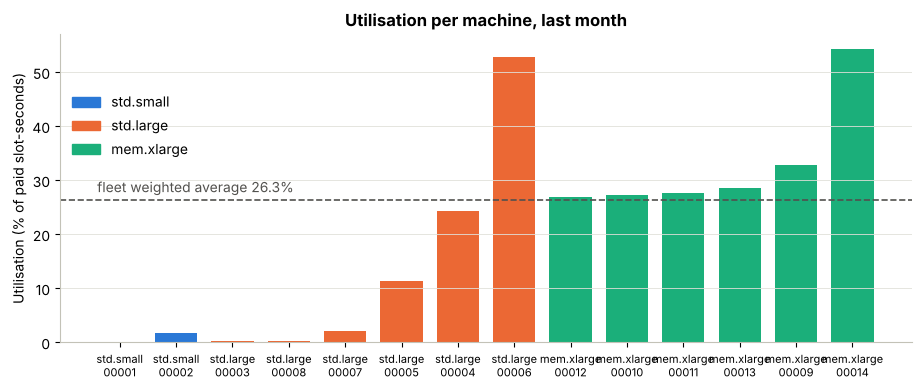

In [7]:
plot_df = instances.assign(order=instances["instance_type"].map({t: i for i, t in enumerate(TYPE_ORDER)})) \
                   .sort_values(["order", "utilization_recomputed"])
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(range(len(plot_df)), plot_df["utilization_recomputed"] * 100,
       color=[TYPE_COLORS[t] for t in plot_df["instance_type"]], width=0.75)
ax.axhline(fleet_util["utilisation_weighted"] * 100, color="#52514e", linestyle="--", linewidth=1.2)
ax.text(-0.4, fleet_util["utilisation_weighted"] * 100 + 1.5,
        f"fleet weighted average {fleet_util['utilisation_weighted']:.1%}", ha="left", color="#52514e")
ax.set_xticks(range(len(plot_df)))
ax.set_xticklabels(plot_df["instance_id"].str.replace("-od-", "\n"), fontsize=8)
ax.set_ylabel("Utilisation (% of paid slot-seconds)")
ax.set_title("Utilisation per machine, last month")
handles = [plt.Rectangle((0, 0), 1, 1, color=TYPE_COLORS[t]) for t in TYPE_ORDER]
ax.legend(handles, TYPE_ORDER, frameon=False, loc="upper left", bbox_to_anchor=(0.0, 0.85))
ax.grid(axis="x", visible=False)
plt.show()

Each bar is one machine. Even the busiest machine is only just over 54% utilised, and several `std.large` machines and both `std.small` machines are close to zero.

## 7. Cross-check: busy slot-seconds against the query log

Here I check whether `busy_slot_s` equals the total running time of the queries recorded in the query log for each machine.

Utilisation is the key number for the idle-cost question, so I wanted to confirm it from two separate files. In the engine, `busy_slot_s` increases by each query's runtime when the query completes (and by the partial runtime if a machine is killed in the middle of a query). Since every historical query completed in one attempt (Notebook 4), `busy_slot_s` should equal `sum(run_s)` for each `instance_id`.

I load only `instance_id` and `run_s` from the query log and add them up by instance. The tolerance allows for each `run_s` being rounded to 1 ms in the CSV.

In [8]:
query_runs = pd.read_csv(HISTORY_DIR / "query_log.csv.gz", usecols=["instance_id", "run_s", "status"])
run_by_instance = query_runs.loc[query_runs["status"] == "completed"].groupby("instance_id")["run_s"].agg(["sum", "size"])
cross = instances.set_index("instance_id")[["instance_type", "busy_slot_s"]].join(run_by_instance)
cross["difference_s"] = cross["busy_slot_s"] - cross["sum"]
print(f"Largest absolute difference: {cross['difference_s'].abs().max():.3f} slot-seconds")
assert cross["difference_s"].abs().max() < 1.0
cross.rename(columns={"sum": "query_log_run_s", "size": "queries_run"})

Largest absolute difference: 0.109 slot-seconds


,instance_type,busy_slot_s,query_log_run_s,queries_run,difference_s
instance_id,,,,,
std.small-od-00001,std.small,106.2000,106.1770,348,0.0230
std.small-od-00002,std.small,"91,057.4000","91,057.3840",299780,0.0160
std.large-od-00003,std.large,"38,079.6000","38,079.6050",638,-0.0050
std.large-od-00004,std.large,"5,053,619.2000","5,053,619.3090",120288,-0.1090
std.large-od-00005,std.large,"2,374,396.4000","2,374,396.4210",56327,-0.0210
std.large-od-00006,std.large,"10,968,748.3000","10,968,748.2490",210566,0.0510
std.large-od-00007,std.large,"451,784.4000","451,784.4220",10757,-0.0220
std.large-od-00008,std.large,"52,804.1000","52,804.1070",1086,-0.0070
mem.xlarge-od-00009,mem.xlarge,"13,631,349.7000","13,631,349.6900",14221,0.0100


For every machine, the total run time from the query log matches `busy_slot_s` to within a fraction of a second, which is just rounding.

The `queries_run` column also shows how much work each machine did. The two `std.small` machines handled all of the roughly 300,000 `lookup` queries, but these are so short (about 0.3 seconds) that they hardly show up as busy time.

So utilisation is confirmed by two independent files.

## 8. Cost allocation: start-up, execution and ready-idle time

In this section I split the \$14,883.50 between three uses of paid time.

For each machine, I use these definitions:

| component | meaning | slot-seconds |
|---|---|---|
| Start-up | launched but not ready yet (booting + warming) | `startup_s * slots` |
| Execution | slots running queries | `busy_slot_s` |
| Ready-idle | ready, but slots not running queries | `ready_time_s * slots - busy_slot_s` |

These three add up exactly to `available_slot_s = billed_s * slots` (I check this), so nothing is counted twice.

To allocate the cost, I spread each machine's cost evenly over its paid slot-seconds. That is, `cost per slot-second = cost_usd / available_slot_s`, and each component gets `component_slot_s * cost per slot-second`.

There are a few assumptions behind this that are worth being clear about:

- It assumes a slot-second costs the same whether the other slots are busy or not. In reality, a machine is rented as a whole, and you cannot pay for half of it. So the "ready-idle cost" is an **accounting allocation**, not an amount that could be saved one slot at a time.
- A machine with 1 of its 16 slots busy still has 15 idle slots in this calculation, even though the machine as a whole is in use. That is the right view for a scheduler that can choose machine sizes and pack work together, but it is not the same as "money wasted on completely empty machines". The instance log cannot tell me how long each machine was *entirely* empty; it only has totals.
- **Ready-idle time is not automatically waste.** Some free capacity is needed so that tight-SLA queries can start immediately (`lookup` 1.5 s, `dashboard` 10 s), and so that bursts can be absorbed. The real question for the scheduler is how much spare capacity is worth paying for, and at which times.

In [9]:
instances["startup_slot_s"] = instances["startup_s"] * instances["slots"]
instances["idle_ready_slot_s"] = instances["ready_slot_s"] - instances["busy_slot_s"]
parts_sum = instances["startup_slot_s"] + instances["busy_slot_s"] + instances["idle_ready_slot_s"]
assert np.allclose(parts_sum, instances["available_slot_s"]), "components do not add to available slot-seconds"

cost_per_slot_s = instances["cost_usd"] / instances["available_slot_s"]
instances["startup_cost"] = instances["startup_slot_s"] * cost_per_slot_s
instances["execution_cost"] = instances["busy_slot_s"] * cost_per_slot_s
instances["idle_ready_cost"] = instances["idle_ready_slot_s"] * cost_per_slot_s

components = ["startup_cost", "execution_cost", "idle_ready_cost"]
allocation = instances.groupby("instance_type")[components + ["cost_usd"]].sum().loc[TYPE_ORDER]
allocation.loc["fleet total"] = allocation.sum()
for c in components:
    allocation[c.replace("_cost", "_pct")] = allocation[c] / allocation["cost_usd"] * 100
assert np.allclose(allocation[components].sum(axis=1), allocation["cost_usd"]), "allocation does not reconcile"
allocation

,startup_cost,execution_cost,idle_ready_cost,cost_usd,startup_pct,execution_pct,idle_ready_pct
instance_type,,,,,,,
std.small,0.0075,1.2662,143.2263,144.5000,0.0052,0.8762,99.1186
std.large,0.2720,447.1810,"2,500.3470","2,947.8000",0.0092,15.1700,84.8208
mem.xlarge,2.5840,"3,882.5353","7,906.0807","11,791.2000",0.0219,32.9274,67.0507
fleet total,2.8635,"4,330.9825","10,549.6540","14,883.5000",0.0192,29.0992,70.8815


Looking at the fleet total row:

- **Execution: about \$4,331 (29%)** of the bill paid for slot-time that ran queries.
- **Ready-idle: about \$10,550 (71%)** paid for ready slots that ran nothing.
- **Start-up: about \$2.86 (0.02%)**. This is tiny here, because each machine started only once and then ran for a month.
- The three components add up to exactly \$14,883.50.

By type, `mem.xlarge` carries most of the idle cost (about \$7,906), simply because it is the most expensive machine. `std.small` is almost entirely idle in slot terms, but it costs very little.

So my answer to "how much paid for machines sitting idle?" is that roughly **\$10.5k of the \$14.9k bought capacity that was ready but unused**. I want to be careful with this number. Part of it was spare capacity that was genuinely needed for tight-SLA work and bursts. However, most of it built up at night and at weekends, when traffic was only a fraction of the weekday peak (Notebooks 1, 3 and 4), and a scheduler that scales could avoid that.

**In a scheduler that scales, start-up cost would be much larger** than it is here, because every launch pays `join_s + ready_s` again (570 seconds for a `mem.xlarge`, which is about \$0.43 on-demand per launch). That cost, and the delay that comes with it, is the price of being able to scale.

### 8.1 Chart: where the money went

I used one stacked horizontal bar per machine type, so the chart shows each type's total and how it splits. A thin white gap separates the pieces.

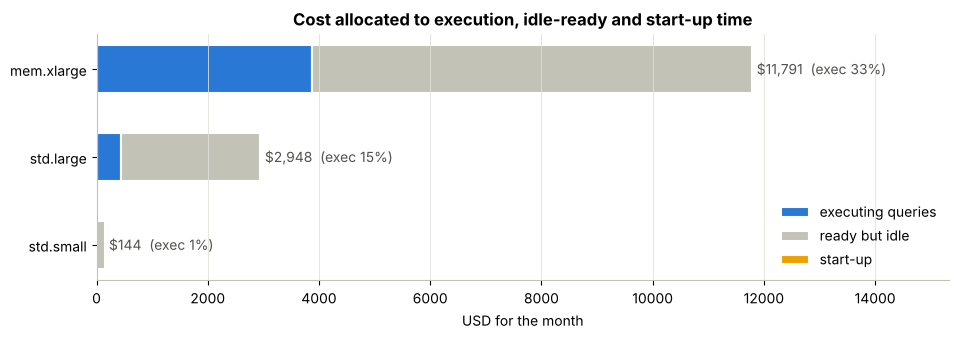

In [10]:
part_colors = {"execution_cost": "#2a78d6", "idle_ready_cost": "#c3c2b7", "startup_cost": "#eda100"}
part_labels = {"execution_cost": "executing queries", "idle_ready_cost": "ready but idle", "startup_cost": "start-up"}
rows = allocation.loc[TYPE_ORDER]
fig, ax = plt.subplots(figsize=(11, 3.2))
left = np.zeros(len(rows))
for c in ["execution_cost", "idle_ready_cost", "startup_cost"]:
    ax.barh(rows.index, rows[c], left=left, color=part_colors[c], label=part_labels[c],
            height=0.55, edgecolor="white", linewidth=1.5)
    left += rows[c].to_numpy()
for y, (t, total) in enumerate(rows["cost_usd"].items()):
    ax.text(total + 80, y, f"${total:,.0f}  (exec {rows.loc[t, 'execution_pct']:.0f}%)", va="center", color="#52514e")
ax.set_xlim(0, rows["cost_usd"].max() * 1.3)
ax.set_xlabel("USD for the month")
ax.set_title("Cost allocated to execution, idle-ready and start-up time")
ax.legend(frameon=False, loc="lower right")
ax.grid(axis="y", visible=False)
plt.show()

Blue is slot-time that ran queries, grey is ready capacity that was not used, and the start-up piece is too small to see. Grey takes up most of every row.

## 9. Summary of findings

**What I observed**

- There were 14 on-demand machines (2 `std.small`, 6 `std.large` and 6 `mem.xlarge`, with 148 slots). All of them were launched at `t = 0` and terminated at `t = 2,601,000 s` with the reason `end_of_simulation`.
- The scheduler never terminated a machine, and there were no spot machines and no spot interruptions.
- Start-up delays were 135 s, 240 s and 570 s, exactly `join_s + ready_s`.
- The total cost of \$14,883.50 matches the bill, and `busy_slot_s` matches the query log.
- **Weighted fleet utilisation was about 26.3%**: `mem.xlarge` about 32.9%, `std.large` about 15.2% and `std.small` about 0.9%.
- The cost split was **about 29% execution, 71% ready-idle and 0.02% start-up**.

**How I interpret this**

- The fleet was mostly paying for unused capacity, because its size never followed demand.
- The uneven utilisation within each type shows that the last few machines in each pool were rarely needed on average. However, the queue data in Notebook 3 shows that they were needed at peaks, and that even more capacity was needed then.

**Limitations**

- The file only has totals per machine. It does not show when each machine was busy or completely empty (Notebook 3 has 5-minute snapshots per type).
- The idle-cost split is an allocation. Real savings depend on removing whole machines at the right times.
- There is no spot history.

**What this means for the scheduler**

- Scale the pools with demand (time of day, day of the week and queue length) instead of using a fixed fleet.
- Keep a small always-on buffer where SLAs are only seconds long. Pools for long-SLA work can scale as needed, because a 9.5-minute start-up is small compared with SLAs of 30 minutes to 12 hours.
- Release machines when the work is done, including at the end of the month.